# TerraSpectra — mid-project review

Think of our data as books, RAM as a desk, and the GIS grid as a classroom seating chart. Today we check the books, measure desk space, and check the seating chart. We do not train a new final model or claim real farm locations.

## 1. Find the project
Open this notebook in VS Code and choose the project `.venv` Python kernel. The small report is already included. Reading it needs no dataset download. Re-running the full audit needs the local Week 1 data and ZIP.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "reports/mid_review/audit.json").exists(), "Open inside the tspectra repository"
sys.path.insert(0, str(ROOT / "src"))
report = json.loads((ROOT / "reports/mid_review/audit.json").read_text())
print(report["environment"])
print("Recorded:", report.get("generated_at_utc", "See Git history"))

{'python': '3.9.6', 'torch': '2.8.0', 'platform': 'macOS-15.2-arm64-arm-64bit', 'device': 'CPU'}
Recorded: 2026-11-11T09:16:55.218509+00:00


## 2. Did every book arrive unchanged?
The audit reads all 900 ZIP members in chunks and compares SHA-256 fingerprints with both the extracted TIFFs and the manifest. It also checks every prepared array. These outputs are the recorded audit results, not a new scan each time you open this notebook.

In [2]:
extraction = report["extraction"]
print("Files checked:", extraction["files_checked"])
print("Integrity passed:", extraction["integrity_passed"])
print("Raw bands:", extraction["raw_band_counts"])
print("Splits:", extraction["split_counts"])
print("Exact duplicates across splits:", extraction["exact_duplicate_hash_overlap"])
print("Recognized EPSG codes:", extraction["recognized_epsg_counts"])

Files checked: 900
Integrity passed: True
Raw bands: {'125': 741, '126': 159}
Splits: {'train': 480, 'validation': 120, 'unlabelled': 300}
Exact duplicates across splits: {'train / validation': 0, 'train / unlabelled': 0, 'unlabelled / validation': 0}
Recognized EPSG codes: {'None': 900}


A result of zero exact duplicates is useful, but nearby pieces cut from the same source image may still be very similar. An unknown CRS also means we cannot confidently put the dataset images on our demonstration farm.

## 3. How much desk space does a batch need?
A float32 number takes four bytes. A model input is a small stack of 16 PCA pages, each 16 × 16 pixels. One batch contains several stacks. PCA pages mix original spectral bands; they are not individual wavelengths.

In [3]:
batch = 16
input_bytes = batch * 1 * 16 * 16 * 16 * 4
print("Input-only memory:", input_bytes / 1024**2, "MiB")
print("This excludes activations, gradients, optimizer, Python and cached data.")

Input-only memory: 0.25 MiB
This excludes activations, gradients, optimizer, Python and cached data.


## 4. What happened in real training steps?
Each batch size ran in a fresh process with a temporary model and actual training inputs. Three forward/backward/Adam steps completed. The Week 2 saved weights stayed unchanged. Peak RSS includes runtime and loaded data, so it is much larger than input memory. Single runs can vary and need not increase perfectly with batch size.

Batch  1: peak 161.2 MiB, 3 steps, finite=True
Batch  8: peak 225.4 MiB, 3 steps, finite=True
Batch 16: peak 299.9 MiB, 3 steps, finite=True
Batch 32: peak 307.0 MiB, 3 steps, finite=True


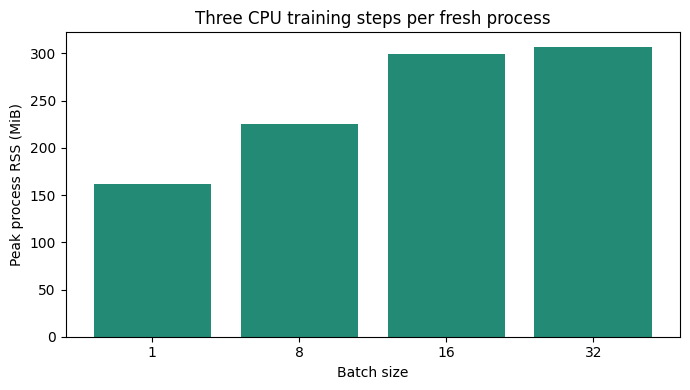

In [4]:
trials = report["memory_trials"]
for trial in trials:
    print(f"Batch {trial['batch_size']:2}: peak {trial['peak_process_rss_mib']:.1f} MiB, "
          f"{trial['steps']} steps, finite={trial['finite_loss_and_gradients']}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(t["batch_size"]) for t in trials], [t["peak_process_rss_mib"] for t in trials], color="#238b75")
ax.set(xlabel="Batch size", ylabel="Peak process RSS (MiB)", title="Three CPU training steps per fresh process")
fig.tight_layout()
plt.show()

Keep batch 16 as the existing default. This proves our small patch pipeline can complete these bounded CPU trials. It does not prove that a giant satellite cube or a GPU will fit. This notebook does not treat the short trial losses as model accuracy.

## 5. Check the seating chart
Our synthetic map has 8 rows and 10 columns. Longitude goes first, latitude second. Mock row zero starts at the bottom (south), but raster row zero starts at the top (north). The flip is `raster_row = rows - 1 - mock_row`. Rasterio independently calculates corners and center coordinates for comparison.

In [5]:
from terraspectra.review import gis_audit
current_gis = gis_audit()
print(json.dumps(current_gis, indent=2))

{
  "cells_checked": 80,
  "max_corner_error_degrees": 0.0,
  "tolerance_degrees": 1e-09,
  "boundary_matches": true,
  "center_roundtrips_passed": true,
  "grid_alignment_passed": true,
  "crs": "EPSG:4326",
  "real_farm_alignment": "NOT VALIDATED: synthetic boundary, no surveyed control points",
  "browser_camera_alignment": "NOT VERIFIED: requires live Mapbox pan/zoom/tilt check",
  "row_convention": "Mock rows start south; raster rows start north."
}


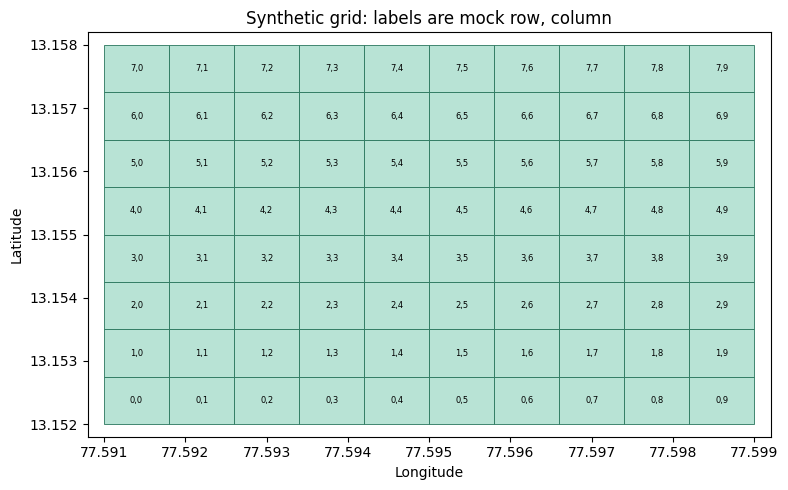

In [6]:
from matplotlib.patches import Rectangle
grid = json.loads((ROOT / "frontend/public/mock-heatmap.json").read_text())
fig, ax = plt.subplots(figsize=(8, 5))
for cell in grid["cells"]:
    w, s, e, n = cell["bounds"]
    ax.add_patch(Rectangle((w,s), e-w, n-s, facecolor="#b8e3d5", edgecolor="#28755c", linewidth=0.6))
    ax.text((w+e)/2, (s+n)/2, f"{cell['row']},{cell['column']}", ha="center", va="center", fontsize=6)
w,s,e,n = grid["bounds"]
ax.set(xlim=(w-0.0002,e+0.0002), ylim=(s-0.0002,n+0.0002), xlabel="Longitude", ylabel="Latitude", title="Synthetic grid: labels are mock row, column")
ax.ticklabel_format(useOffset=False)
fig.tight_layout()
plt.show()

## 6. Three different kinds of map proof

- **Numerical geometry:** checked above for all 80 synthetic cells.
- **Live browser rendering:** still needs a Mapbox token and a manual pan/zoom/rotate/tilt check. The diagram above cannot prove WebGL alignment.
- **Actual farm registration:** needs surveyed reference points and trustworthy image georeferencing. These resources are not supplied.

Our conclusion is deliberately limited: the demonstration grid coordinates agree, but real-farm placement is unvalidated.

## 7. Optional: repeat the complete audit
Leave the switch off to avoid rescanning the ZIP whenever you run the notebook. If you turn it on, it checks local files and runs four short CPU trials, then updates the JSON reports. Rerun earlier display cells to view the new results.

In [7]:
RUN_FULL_AUDIT = False
if RUN_FULL_AUDIT:
    import os
    import subprocess
    archive = Path.home() / "Downloads/beyond-visible-spectrum-ai-for-agriculture-P1.zip"
    environment = dict(os.environ, PYTHONPATH=str(ROOT / "src"))
    subprocess.run([sys.executable, "-m", "terraspectra.review", "--zip", str(archive)],
                   cwd=ROOT, env=environment, check=True)
else:
    print("Using the committed audit report; no new training trials requested.")

Using the committed audit report; no new training trials requested.


## What to tell your mentor
“I checked the original files, the prepared arrays, and the memory needed by actual training steps. I also checked the synthetic map grid against independently calculated coordinates. I separated what passed from what needs real-world evidence.”

Read [the guide](../docs/MID_PROJECT_REVIEW.md) for commands and manual GIS checks, and [the research notes](../docs/MID_PROJECT_RESEARCH.md) for primary references from PyTorch, Python, Rasterio, GeoJSON and Deck.gl.